# Chapter 6 · Monte Carlo pricing and its error: interactive demos

Companion to Chapter 6 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/06-monte-carlo.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import time
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import bs
from mfe230d import montecarlo as mc
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN = "#1BAF7A"
TC = bs.TEST_CASE          # S = K = 100, T = 1, r = 1%, y = 2%, sigma = 20%

## 1. Bare-bones Monte Carlo and its standard error

The course's bare-bones Monte Carlo for the Black–Scholes call: draw $n$ normals, build $S_T$ exactly, average the
discounted payoffs. One stream of draws is read at $n = 2, 4, 8, \dots$; the dots are the actual errors against the
closed form, the lines the standard errors (Theorem 6.4 and Proposition 6.8 in the notes). The errors scatter around
the standard error, on a line of slope $-1/2$.

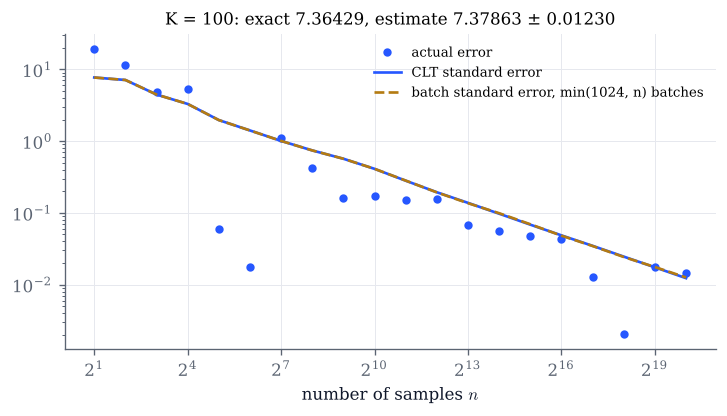

In [2]:
def convergence(seed=2024, K=100.0, log2_nmax=20, m=1024):
    p = dict(TC, K=K)
    ns = 2 ** np.arange(1, log2_nmax + 1)
    out = mc.bs_call_bbmc(**p, n=ns[-1], seed=seed)
    x = np.exp(-p["r"] * p["T"]) * out["samples"]["CT"]
    est = mc.nested_estimates(x, ns, m=m)
    exact = float(bs.call(**p))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(ns, np.abs(est["mean"] - exact), "o", color=COBALT, ms=4, label="actual error")
    ax.plot(ns, est["se"], color=COBALT, label="CLT standard error")
    ax.plot(ns, est["se_batch"], color=GOLD, ls="--", label=f"batch standard error, min({m}, n) batches")
    ax.set(xscale="log", yscale="log", xlabel="number of samples $n$",
           title=f"K = {K:g}: exact {exact:.5f}, estimate {est['mean'][-1]:.5f} ± {est['se'][-1]:.5f}")
    ax.set_xscale("log", base=2)
    ax.legend(fontsize=8)
    plt.show()

convergence()

In [3]:
# Explore: change the seed, the strike and the number of batches. Deep out-of-the-money strikes need many more paths.
interact(convergence,
         seed=IntSlider(value=2024, min=0, max=5000, continuous_update=False, description="seed"),
         K=FloatSlider(value=100.0, min=60.0, max=200.0, step=5.0, continuous_update=False, description="strike K"),
         log2_nmax=IntSlider(value=20, min=8, max=22, continuous_update=False, description="log2 n max"),
         m=Dropdown(options=[8, 32, 128, 1024], value=1024, description="batches"));

## 2. Does the 95% interval cover 95% of the time?

For each of 2000 independent samples of size $n$ we compute the studentised error
$T_n = \sqrt n(\hat X_n-\mu)/\hat s_n$ and check whether $|T_n|\le 1.96$. The histogram of $T_n$ is compared with the
standard normal density. For a call the coverage reaches 95% quickly; for a digital with a far strike the payoff is
a rare event, and the interval is unreliable until the expected number of hits $np$ is large (Remark 6.6).

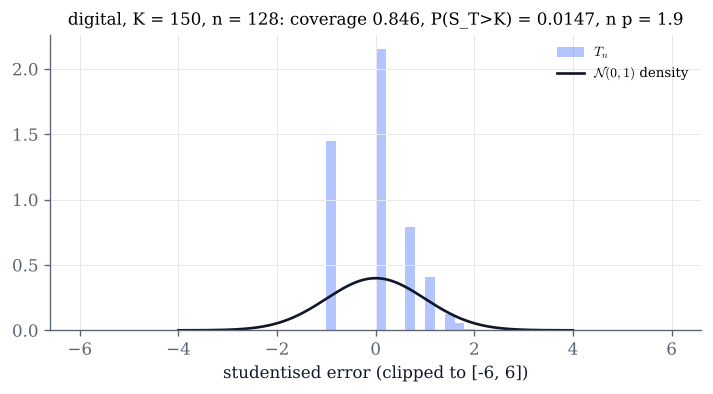

In [4]:
def coverage_demo(payoff="digital", K=150.0, log2_n=7, reps=2000, seed=1):
    S, T, r, y, sig = (TC[k] for k in ("S", "T", "r", "y", "sigma"))
    n = 2 ** log2_n
    rng = np.random.default_rng(seed)
    ST = mc.terminal_prices(S, T, r, y, sig, rng.standard_normal((reps, n)))
    if payoff == "call":
        X = np.exp(-r * T) * np.maximum(ST - K, 0.0)
        mu = float(bs.call(S, K, T, r, y, sig))
    else:
        X = (ST > K).astype(float)
        mu = float(np.exp(r * T) * bs.digital_call(S, K, T, r, y, sig))
    mean, sd = X.mean(axis=1), X.std(axis=1, ddof=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Tn = np.where(sd > 0, np.sqrt(n) * (mean - mu) / sd, 0.0)
    covered = np.abs(mean - mu) <= 1.96 * sd / np.sqrt(n)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.hist(np.clip(Tn, -6, 6), bins=60, range=(-6, 6), density=True, color=COBALT, alpha=0.35, label="$T_n$")
    g = np.linspace(-4, 4, 400)
    ax.plot(g, np.exp(-g**2 / 2) / np.sqrt(2 * np.pi), color=INK, label="$\\mathcal{N}(0,1)$ density")
    extra = f", P(S_T>K) = {mu:.4f}, n p = {n * mu:.1f}" if payoff == "digital" else ""
    ax.set(xlabel="studentised error (clipped to [-6, 6])",
           title=f"{payoff}, K = {K:g}, n = {n}: coverage {covered.mean():.3f}{extra}")
    ax.legend(fontsize=8)
    plt.show()

coverage_demo()

In [5]:
interact(coverage_demo,
         payoff=Dropdown(options=["call", "digital"], value="digital", description="payoff"),
         K=FloatSlider(value=150.0, min=60.0, max=220.0, step=5.0, continuous_update=False, description="strike K"),
         log2_n=IntSlider(value=7, min=2, max=13, continuous_update=False, description="log2 n"),
         reps=IntSlider(value=2000, min=500, max=5000, step=500, continuous_update=False, description="samples"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Heavy tails: the running mean and the sample standard deviation

Pareto samples, $P(X>x)=x^{-\alpha}$ for $x\ge1$, drawn by inversion. The mean $\alpha/(\alpha-1)$ is finite for
$\alpha>1$, the variance only for $\alpha>2$ (Theorem 6.4 and Remark 6.7). Watch the running mean jump when a
large sample arrives, and the sample standard deviation $\hat s_n$ climb instead of settling.

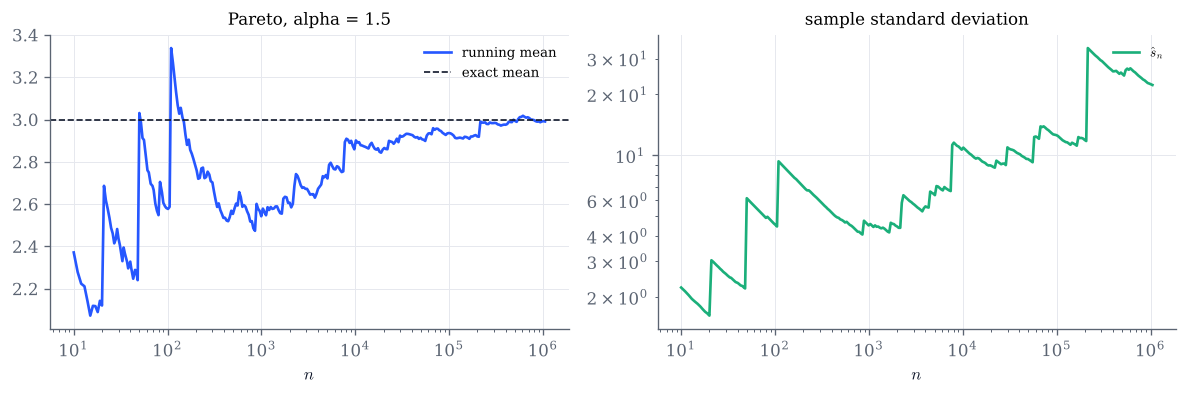

In [6]:
def heavy_tails(alpha=1.5, seed=11, log2_nmax=20):
    n = 2 ** log2_nmax
    x = mc.pareto(alpha, n, seed=seed)
    k = np.arange(1, n + 1)
    run_mean = np.cumsum(x) / k
    grid = np.unique(np.logspace(1, np.log10(n), 300).astype(int))
    c1, c2 = np.cumsum(x)[grid - 1], np.cumsum(x**2)[grid - 1]
    sd = np.sqrt((c2 - c1**2 / grid) / (grid - 1))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(grid, run_mean[grid - 1], color=COBALT, label="running mean")
    if alpha > 1:
        ax.axhline(alpha / (alpha - 1), color=INK, ls="--", lw=1, label="exact mean")
    ax.set(xscale="log", xlabel="$n$", title=f"Pareto, alpha = {alpha:g}")
    ax.legend(fontsize=8)
    ax2.plot(grid, sd, color=GREEN, label="$\\hat s_n$")
    if alpha > 2:
        ax2.axhline(np.sqrt(alpha / ((alpha - 1) ** 2 * (alpha - 2))), color=INK, ls="--", lw=1, label="exact $\\sigma$")
    ax2.set(xscale="log", yscale="log", xlabel="$n$", title="sample standard deviation")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

heavy_tails()

In [7]:
interact(heavy_tails,
         alpha=FloatSlider(value=1.5, min=1.05, max=4.0, step=0.05, continuous_update=False, description="alpha"),
         seed=IntSlider(value=11, min=0, max=200, continuous_update=False, description="seed"),
         log2_nmax=IntSlider(value=20, min=10, max=22, continuous_update=False, description="log2 n max"));

## 4. Efficiency and overheads on your machine

The efficiency of an estimator is $1/(\sigma^2\tau)$, with $\tau$ the cost per sample (Definition 6.9). Here we time
the bare-bones Monte Carlo for $n=2,4,\dots,2^{20}$ and plot its efficiency relative to the largest run, as in the
course's experiment (Remark 6.10). The per-sample variance hardly changes with $n$, so the curve shows the cost per
sample: a fixed overhead per run makes short runs look inefficient. Your numbers depend on your machine.

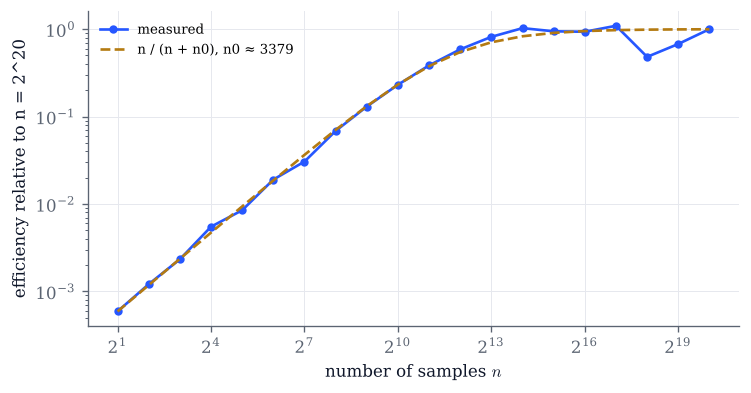

In [8]:
def efficiency_vs_n(log2_nmax=20, repeats=5, seed=0):
    ns = 2 ** np.arange(1, log2_nmax + 1)
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(ns))                 # randomised order, as in the course, against drifts
    times = np.empty(len(ns))
    for i in order:
        best = np.inf
        for _ in range(repeats):
            t0 = time.perf_counter()
            mc.bs_call_bbmc(**TC, n=int(ns[i]), seed=seed)
            best = min(best, time.perf_counter() - t0)
        times[i] = best
    per_sample = times / ns
    sd = np.sqrt(mc.payoff_moments_quadrature(lambda s: np.maximum(s - TC["K"], 0.0),
                                              TC["S"], TC["T"], TC["r"], TC["y"], TC["sigma"])[1])
    eff = (sd**2 * per_sample[-1]) / (sd**2 * per_sample)     # relative to the largest n
    n0 = np.median(times[:5]) / per_sample[-1]                 # overhead, in units of samples
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(ns, eff, "o-", color=COBALT, ms=4, label="measured")
    ax.plot(ns, ns / (ns + n0), color=GOLD, ls="--", label=f"n / (n + n0), n0 ≈ {n0:.0f}")
    ax.set(xscale="log", yscale="log", xlabel="number of samples $n$",
           ylabel=f"efficiency relative to n = 2^{log2_nmax}")
    ax.set_xscale("log", base=2)
    ax.legend(fontsize=8)
    plt.show()

efficiency_vs_n()

In [9]:
interact(efficiency_vs_n,
         log2_nmax=IntSlider(value=20, min=12, max=22, continuous_update=False, description="log2 n max"),
         repeats=IntSlider(value=5, min=1, max=20, continuous_update=False, description="repeats"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 5. Product rules against Monte Carlo

The integrand $f(x)=\prod_{j=1}^d e^{x_j}/(e-1)$ on $[0,1]^d$ has integral 1 and Monte Carlo variance
$\big(\tfrac{e+1}{2(e-1)}\big)^d-1$. The product midpoint rule with $N=k^d$ points has error of order $N^{-2/d}$,
Monte Carlo of order $N^{-1/2}$ (Proposition 6.14). Pick the dimension and see where the lines cross.

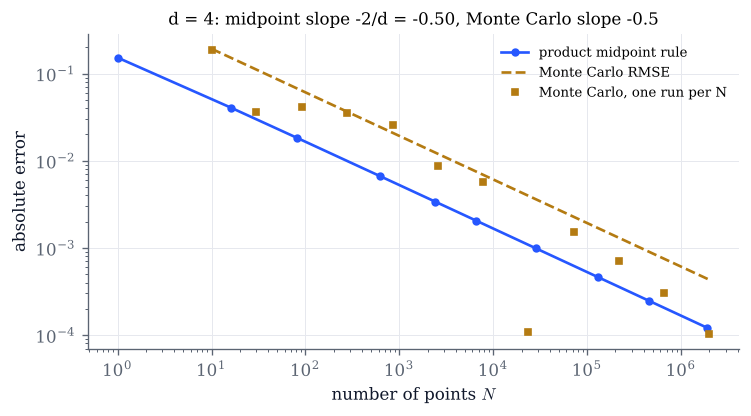

In [10]:
def quadrature_vs_mc(d=4, seed=0):
    f = lambda x: np.prod(np.exp(x) / (np.e - 1), axis=-1)
    var = ((np.e + 1) / (2 * (np.e - 1))) ** d - 1
    kmax = int(np.floor((2e6) ** (1 / d)))
    ks = np.unique(np.geomspace(1, kmax, 12).astype(int))
    N = ks.astype(float) ** d
    quad = [abs(mc.product_midpoint(f, d, int(k)) - 1) for k in ks]
    Nmc = np.unique(np.geomspace(10, 2e6, 12).astype(int))
    mc_err = [abs(mc.mc_integrate(f, d, int(n), seed=seed + i)["mean"] - 1) for i, n in enumerate(Nmc)]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(N, quad, "o-", color=COBALT, ms=4, label="product midpoint rule")
    ax.plot(Nmc, np.sqrt(var / Nmc), color=GOLD, ls="--", label="Monte Carlo RMSE")
    ax.plot(Nmc, mc_err, "s", color=GOLD, ms=4, label="Monte Carlo, one run per N")
    ax.set(xscale="log", yscale="log", xlabel="number of points $N$", ylabel="absolute error",
           title=f"d = {d}: midpoint slope -2/d = {-2 / d:.2f}, Monte Carlo slope -0.5")
    ax.legend(fontsize=8)
    plt.show()

quadrature_vs_mc()

In [11]:
interact(quadrature_vs_mc,
         d=IntSlider(value=4, min=1, max=10, continuous_update=False, description="dimension d"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, move the strike to 180 or 200. What happens to the error and to the standard error while no path has
  finished in the money, and when the first one does?
- In section 2, choose the call with $K=60$ and with $K=200$. Which payoff is more skewed, and how does that show in the
  histogram of $T_n$?
- In section 3, compare $\alpha=2.1$ with $\alpha=1.9$. Can you tell from one run whether the variance is finite?
- In section 4, run the experiment twice. How stable is the estimated overhead $n_0$, and what does it mean for comparing
  two methods by their measured running times?
- In section 5, find the smallest $d$ for which Monte Carlo is more accurate than the product rule at $N=10^6$ for this
  integrand.